# Exercícios Aula 05 – Apache Spark
Food Establishment Inspection Data (King County) – versão atualizada, processada no Amazon EMR com PySpark e Spark SQL.

In [1]:
from pyspark.sql import functions as F

# Rotas de entrada e saída no Amazon S3
data_source = "s3://bucket-andre-lab1/Food_Establishment_Inspection_Data_20261022.csv"
output_uri = "s3://bucket-andre-lab1/output/"

# Ler tudo como string: inferSchema transformaria Zip Code e Parcel Number em inteiros (perdendo zeros à esquerda)
# e não reconhece a data no formato MM/dd/yyyy
raw_df = spark.read.option("header", "true").csv(data_source)

# Padronizar nomes das colunas para snake_case ("Inspection Date" -> inspection_date)
raw_df = raw_df.toDF(*[c.strip().lower().replace(" ", "_") for c in raw_df.columns])
raw_df.printSchema()

Starting Spark application


ID,YARN Application ID,Kind,State,Spark UI,Driver log,User,Current session?
0,application_1792705076003_0001,pyspark,idle,Link,Link,None,✔


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

SparkSession available as 'spark'.


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

root
 |-- name: string (nullable = true)
 |-- program_identifier: string (nullable = true)
 |-- inspection_date: string (nullable = true)
 |-- classification: string (nullable = true)
 |-- address: string (nullable = true)
 |-- city: string (nullable = true)
 |-- zip_code: string (nullable = true)
 |-- inspection_type: string (nullable = true)
 |-- inspection_score: string (nullable = true)
 |-- inspection_result: string (nullable = true)
 |-- inspection_closed_business: string (nullable = true)
 |-- seating_range: string (nullable = true)
 |-- risk_category: string (nullable = true)
 |-- violation_type: string (nullable = true)
 |-- violation_description: string (nullable = true)
 |-- violation_points: string (nullable = true)
 |-- grade: string (nullable = true)
 |-- parcel_number: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- inspection_serial_num: string (nullable = true)

## 1. Estrutura e qualidade dos dados

In [2]:
# Converter tipos e padronizar texto
restaurants_df = (raw_df
    .withColumn("inspection_date", F.to_date("inspection_date", "MM/dd/yyyy"))
    .withColumn("inspection_score", F.col("inspection_score").cast("int"))
    .withColumn("violation_points", F.col("violation_points").cast("int"))
    .withColumn("risk_category", F.col("risk_category").cast("int"))
    .withColumn("inspection_closed_business", F.col("inspection_closed_business") == "Yes")
    .withColumn("city", F.upper(F.trim("city")))
    .withColumn("violation_type", F.upper(F.trim("violation_type")))
    .cache())

print(f"Registros: {restaurants_df.count()}")
print(f"Colunas: {len(restaurants_df.columns)}")
restaurants_df.printSchema()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

Registros: 110068
Colunas: 20
root
 |-- name: string (nullable = true)
 |-- program_identifier: string (nullable = true)
 |-- inspection_date: date (nullable = true)
 |-- classification: string (nullable = true)
 |-- address: string (nullable = true)
 |-- city: string (nullable = true)
 |-- zip_code: string (nullable = true)
 |-- inspection_type: string (nullable = true)
 |-- inspection_score: integer (nullable = true)
 |-- inspection_result: string (nullable = true)
 |-- inspection_closed_business: boolean (nullable = true)
 |-- seating_range: string (nullable = true)
 |-- risk_category: integer (nullable = true)
 |-- violation_type: string (nullable = true)
 |-- violation_description: string (nullable = true)
 |-- violation_points: integer (nullable = true)
 |-- grade: string (nullable = true)
 |-- parcel_number: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- inspection_serial_num: string (nullable = true)

In [3]:
# Valores ausentes por coluna
restaurants_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in restaurants_df.columns]).show(vertical=True)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

-RECORD 0---------------------------
 name                       | 0     
 program_identifier         | 90323 
 inspection_date            | 0     
 classification             | 0     
 address                    | 0     
 city                       | 9     
 zip_code                   | 0     
 inspection_type            | 0     
 inspection_score           | 0     
 inspection_result          | 0     
 inspection_closed_business | 0     
 seating_range              | 23800 
 risk_category              | 676   
 violation_type             | 41011 
 violation_description      | 41011 
 violation_points           | 0     
 grade                      | 0     
 parcel_number              | 465   
 business_id                | 0     
 inspection_serial_num      | 0

In [4]:
# Domínio das colunas categóricas usadas nas análises
restaurants_df.groupBy("violation_type").count().show()
restaurants_df.groupBy("inspection_result").count().show()
restaurants_df.select(F.min("inspection_date"), F.max("inspection_date")).show()

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+--------------+-----+
|violation_type|count|
+--------------+-----+
|          NULL|41011|
|          BLUE|34813|
|           RED|34244|
+--------------+-----+

+-----------------+-----+
|inspection_result|count|
+-----------------+-----+
|         Complete| 2779|
|   Unsatisfactory|53499|
|     Satisfactory|53790|
+-----------------+-----+

+--------------------+--------------------+
|min(inspection_date)|max(inspection_date)|
+--------------------+--------------------+
|          2021-01-04|          2026-10-21|
+--------------------+--------------------+

**Alterações em relação ao dataset do laboratório**

| Laboratório | Dataset atualizado | Ajuste no código |
|---|---|---|
| 5 colunas, nomes em snake_case (`name`, `violation_type`, ...) | 20 colunas, nomes com espaços e maiúsculas (`Violation Type`, `Inspection Date`, ...) | Renomear todas as colunas para snake_case com `toDF` |
| Sem data, cidade ou identificador de inspeção | `Inspection Date`, `City`, `Business_ID`, `Inspection_Serial_Num` | Permitem as análises por cidade, por ano e por inspeção única |
| `inferSchema` suficiente | Data em `MM/dd/yyyy` e códigos numéricos com zeros à esquerda (`Zip Code`, `Parcel Number`) | Ler como string e converter explicitamente (`to_date`, `cast("int")`) |
| `inspection_closed_business` = `TRUE/FALSE` | `Yes/No` | Converter para booleano |
| Cidade inexistente | Mesma cidade com grafias diferentes (`Auburn`/`AUBURN`) | `upper(trim(city))` |

Cada linha continua sendo **uma infração** (ou uma inspeção sem infração, com `violation_type` nulo). Por isso uma mesma inspeção aparece em várias linhas.

In [5]:
restaurants_df.createOrReplaceTempView("restaurant_violations")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

## 2. Infrações RED por estabelecimento

In [6]:
# Agrupar por Business_ID: o nome sozinho junta unidades diferentes de uma mesma rede (ex.: várias lojas SUBWAY)
red_by_establishment = spark.sql("""
    SELECT business_id, first(name) AS name, first(address) AS address, first(city) AS city,
           COUNT(*) AS total_red_violations,
           COUNT(DISTINCT inspection_serial_num) AS inspections_with_red
    FROM restaurant_violations
    WHERE violation_type = 'RED'
    GROUP BY business_id
    ORDER BY total_red_violations DESC
    LIMIT 10
""")
red_by_establishment.show(truncate=False)
red_by_establishment.write.option("header", "true").mode("overwrite").csv(output_uri + "red_by_establishment/")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+--------------+---------------------------------------------+--------------------------------+--------+--------------------+--------------------+
|business_id   |name                                         |address                         |city    |total_red_violations|inspections_with_red|
+--------------+---------------------------------------------+--------------------------------+--------+--------------------+--------------------+
|PFE-PR-3137682|BOMBAY GRILL                                 |12336 LAKE CITY WAY NE          |SEATTLE |53                  |12                  |
|PFE-PR-3127686|RED ONION TAVERN                             |4210 E MADISON ST               |SEATTLE |50                  |12                  |
|PFE-PR-3128874|RUCHI INDIAN RESTAURANT                      |1360 156TH AVE NE               |BELLEVUE|46                  |15                  |
|PFE-PR-3127355|PATIO FINE THAI CUISINE                      |524 15TH AVE E                  |SEATTLE |45            

In [7]:
# Mesma consulta do laboratório (agrupando por nome), para comparação
spark.sql("""
    SELECT name, COUNT(*) AS total_red_violations
    FROM restaurant_violations
    WHERE violation_type = 'RED'
    GROUP BY name
    ORDER BY total_red_violations DESC
    LIMIT 10
""").show(truncate=False)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+------------------------------+--------------------+
|name                          |total_red_violations|
+------------------------------+--------------------+
|T-MOBILE PARK                 |159                 |
|SUBWAY                        |154                 |
|LEVY RESTAURANTS @ LUMEN FIELD|130                 |
|ARENA AT SEATTLE CENTER       |63                  |
|PCC COMMUNITY MARKETS         |59                  |
|ASIAN PACIFIC MARKET AND DELI |54                  |
|BOMBAY GRILL                  |53                  |
|RED ONION TAVERN              |50                  |
|TACO DEL MAR                  |50                  |
|JUST POKE                     |49                  |
+------------------------------+--------------------+

## 3. Infrações RED por cidade

In [8]:
red_by_city = spark.sql("""
    SELECT city, COUNT(*) AS total_red_violations,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM restaurant_violations
    WHERE violation_type = 'RED' AND city IS NOT NULL
    GROUP BY city
    ORDER BY total_red_violations DESC
    LIMIT 10
""")
red_by_city.show(truncate=False)
red_by_city.write.option("header", "true").mode("overwrite").csv(output_uri + "red_by_city/")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+-----------+--------------------+---------+
|city       |total_red_violations|pct_total|
+-----------+--------------------+---------+
|SEATTLE    |16702               |48.77    |
|BELLEVUE   |3087                |9.01     |
|KENT       |2279                |6.66     |
|RENTON     |1357                |3.96     |
|REDMOND    |1179                |3.44     |
|FEDERAL WAY|1083                |3.16     |
|KIRKLAND   |1079                |3.15     |
|TUKWILA    |1020                |2.98     |
|AUBURN     |814                 |2.38     |
|BURIEN     |622                 |1.82     |
+-----------+--------------------+---------+

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

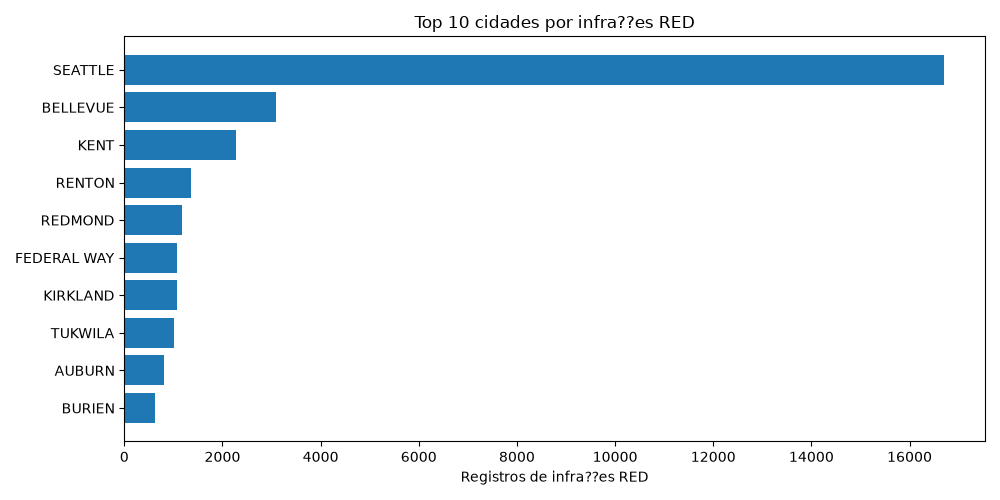

In [9]:
import matplotlib.pyplot as plt

pdf = red_by_city.toPandas()
plt.clf()
plt.figure(figsize=(10, 5))
plt.barh(pdf["city"][::-1], pdf["total_red_violations"][::-1])
plt.xlabel("Registros de infrações RED")
plt.title("Top 10 cidades por infrações RED")
plt.tight_layout()
%matplot plt

## 4. Evolução temporal
Registros de infração (linhas) são diferentes de inspeções únicas (`inspection_serial_num` distintos).

In [10]:
by_year = spark.sql("""
    SELECT year(inspection_date) AS year,
           COUNT(DISTINCT inspection_serial_num) AS unique_inspections,
           COUNT(violation_type) AS violation_records,
           SUM(CASE WHEN violation_type = 'RED' THEN 1 ELSE 0 END) AS red_records,
           COUNT(DISTINCT CASE WHEN violation_type = 'RED' THEN inspection_serial_num END) AS inspections_with_red
    FROM restaurant_violations
    GROUP BY year(inspection_date)
    ORDER BY year
""")
by_year.show()
by_year.write.option("header", "true").mode("overwrite").csv(output_uri + "by_year/")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+----+------------------+-----------------+-----------+--------------------+
|year|unique_inspections|violation_records|red_records|inspections_with_red|
+----+------------------+-----------------+-----------+--------------------+
|2021|              6433|             4280|       2230|                1565|
|2022|              9837|             8906|       4562|                3024|
|2023|             12302|            13106|       6692|                4217|
|2024|             14785|            15314|       7461|                4710|
|2025|             16418|            15581|       7813|                5059|
|2026|             14354|            11870|       5486|                3469|
+----+------------------+-----------------+-----------+--------------------+

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

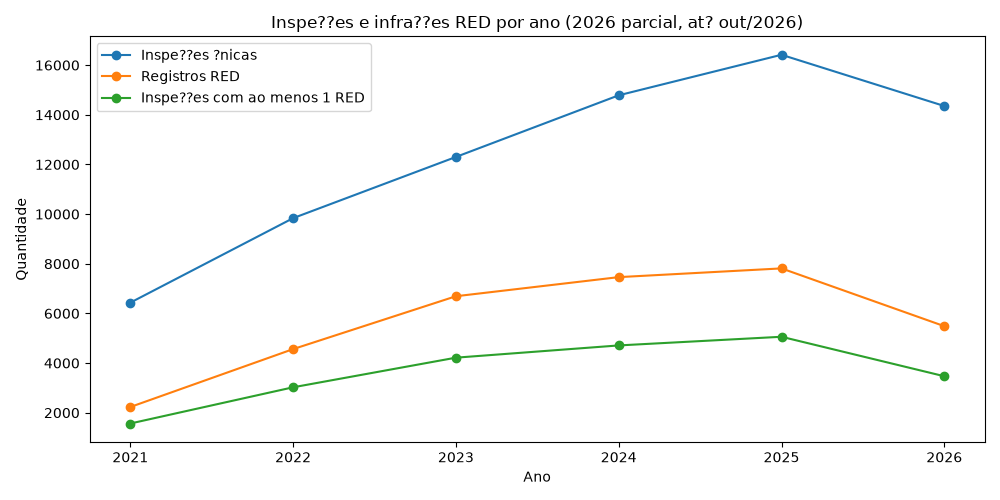

In [11]:
pdf = by_year.toPandas()
plt.clf()
plt.figure(figsize=(10, 5))
for col, label in [("unique_inspections", "Inspeções únicas"), ("red_records", "Registros RED"),
                   ("inspections_with_red", "Inspeções com ao menos 1 RED")]:
    plt.plot(pdf["year"], pdf[col], marker="o", label=label)
plt.xticks(pdf["year"])
plt.xlabel("Ano")
plt.ylabel("Quantidade")
plt.title("Inspeções e infrações RED por ano (2026 parcial, até out/2026)")
plt.legend()
plt.tight_layout()
%matplot plt

## 5. Execução distribuída
Plano físico da consulta da questão 2: os operadores `Exchange` marcam os pontos de shuffle (redistribuição por `business_id` no `GROUP BY` e por ordenação no `ORDER BY ... LIMIT`). Na Spark UI (aba SQL/DataFrame), localize essa consulta e observe os Jobs, Stages, Tasks e Executors correspondentes.

In [12]:
red_by_establishment.explain(mode="formatted")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

== Physical Plan ==
AdaptiveSparkPlan (17)
+- TakeOrderedAndProject (16)
   +- SortAggregate (15)
      +- Sort (14)
         +- Exchange (13)
            +- SortAggregate (12)
               +- SortAggregate (11)
                  +- Sort (10)
                     +- Exchange (9)
                        +- SortAggregate (8)
                           +- Sort (7)
                              +- Project (6)
                                 +- Filter (5)
                                    +- InMemoryTableScan (1)
                                          +- InMemoryRelation (2)
                                                +- * Project (4)
                                                   +- Scan csv  (3)


(1) InMemoryTableScan
Output [6]: [address#62, business_id#76, city#204, inspection_serial_num#77, name#58, violation_type#225]
Arguments: [address#62, business_id#76, city#204, inspection_serial_num#77, name#58, violation_type#225], [isnotnull(violation_type#225), (violation_typ

In [13]:
# Informações do cluster para relacionar com a aba Executors
sc = spark.sparkContext
print("Spark UI:", sc.uiWebUrl)
print("Default parallelism:", sc.defaultParallelism)
print("Partições do DataFrame:", restaurants_df.rdd.getNumPartitions())
print("spark.sql.shuffle.partitions:", spark.conf.get("spark.sql.shuffle.partitions"))

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

Spark UI: http://ip-172-31-41-100.ec2.internal:46569
Default parallelism: 2
Parti??es do DataFrame: 2
spark.sql.shuffle.partitions: 200